# 05 · Complex-word ratio

**Do winning openings use a different share of words with three or more syllables?** Compare the same published training pairs using the same randomized A/B assignments and three OP-discussion-grouped folds.

After Minimal cleaning, divide the number of word occurrences with at least three syllables by the total number of word occurrences. Repetitions count. Reuse the [Flesch syllable counter](../readability/analyze_flesch.py), which uses the first CMUdict pronunciation for listed words and estimates syllables from Pyphen hyphenation for the rest. The fallback is approximate, especially for names, acronyms, and informal spellings. The feature measures syllable count and may reflect topic terminology.

The [standalone script](analyze_complex_word_ratio.py) saves timestamped runs. To regenerate, use the existing word-frequency and Flesch environments with `wordfreq==3.1.1`, `cmudict==1.1.3`, and `pyphen==0.18.1`.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/complex-word-ratio"
SCRIPT = REPO / "project/notebooks/linguistic-features/lexical-complexity/analyze_complex_word_ratio.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")
print(f"{len(pairs):,} complete pairs · {len(openings):,} unique openings · {report['discussions']:,} discussions")
print(f"Three or more syllables: {report['complex_token_share']:.2%} of measured tokens.")
print(f"Used the hyphenation fallback: {report['fallback_token_share']:.2%} of measured tokens.")

3,451 complete pairs · 6,581 unique openings · 2,507 discussions
Three or more syllables: 12.62% of measured tokens.
Used the hyphenation fallback: 0.82% of measured tokens.


## Distribution and examples

Summarize each distinct opening once. Inspect the low and high ends of the distribution and the words that contribute to the ratio.

In [2]:
feature = "complex_word_ratio"
display(openings[[feature, "measured_tokens", "complex_tokens", "fallback_tokens"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).round(3))
examples = pd.concat({
    "Lowest ratios": openings.nsmallest(3, feature),
    "Highest ratios": openings.nlargest(3, feature),
})
display(examples[[feature, "measured_tokens", "complex_examples", "opening_preview"]].round(3))

,complex_word_ratio,measured_tokens,complex_tokens,fallback_tokens
count,6581.000,6581.000,6581.000,6581.000
mean,0.125,234.739,29.618,1.915
std,0.043,193.381,27.208,3.488
min,0.011,40.000,1.000,0.000
1%,0.038,51.000,3.000,0.000
25%,0.096,107.000,12.000,0.000
50%,0.123,176.000,21.000,1.000
75%,0.153,296.000,38.000,2.000
99%,0.241,987.400,138.200,16.000
max,0.343,1724.000,360.000,60.000


complex_word_ratio  measured_tokens                                                                                 complex_examples                                                                                                                                                                                                                                   opening_preview
               comment_id                                                                                                                                                                                                                                                                                                                                                                                        
Lowest ratios  t1_cjx9qkg               0.011               95                                                                                         remember  I get where you're coming from - I've been at that point, my brother's been at that point, I'm sure quite a lot of people have been at that point. But I really started to take pictures once I stopped thinking of taking pictures as a way to 
               t1_cqnfxbg               0.014               71                                                                                        literally  I can see why this might be normal in New York, but keep in mind you're literally in one of the biggest cities in the world. Coming from DC, we have lots of places to sit and eat. That said, I can't see a reason why people always sit and ea
               t1_cgyrejw               0.015               67                                                                                       meaningful  Think of it this way: Just because you are saying goodbye to your girlfriend, does that mean one or more other people have to say goodbye as well? I like to think that when I die I might still be able to do some good. Isn't your goodbye tha
Highest ratios t1_cpjq913               0.343              105  technically, antisocial, personality, disorder, sociopaths, psychopaths, possibly, observations  Technically speaking, someone with antisocial personality disorder (sociopaths and psychopaths) does not (possibly cannot) feel lonely. I would suggest that your observations have been of individuals with bipolar disorder, borderline person
               t1_ccoyngj               0.329               82               remember, athletic, foundations, general, university, athletics, partially, alumni  Remember that many top athletic programs are paid for by athletic foundations, not the general university fund. This means that athletics are at least partially funded by private alumni donations. In the university I support (SEC school), I
               t1_cq6dcu3               0.327               55        basically, comfortable, understanding, ridiculing, communism, anyone, whatever, communist  I'm basically comfortable with that, understanding than when we agree on ridiculing communism, we're not just ridiculing anyone left of Ted Cruz and calling whatever we want to "communism." At this point, with anyone communist/socialist tal

## Paired association and standalone prediction

Report how often the opening with the higher complex-word ratio won among unequal-score pairs. Compute the 95% interval by resampling OP discussions. Repeat within pairs whose opening word counts differ by at most 50 words.

The standalone model predicts whether side A won from the A-minus-B ratio difference. Standardization is fitted inside each training fold. ROC-AUC is the primary metric and A-wins prevalence is the reference for average precision.

In [3]:
metrics = pd.DataFrame({
    "All pairs": report["winner_higher"], "Within 50 words": report["within_50_words"],
}).T
metrics["Winner higher (%)"] = 100 * metrics["winner_higher_rate"].astype(float)
metrics["95% CI lower (%)"] = metrics["ci_95"].map(lambda interval: 100 * interval[0] if interval[0] is not None else np.nan)
metrics["95% CI upper (%)"] = metrics["ci_95"].map(lambda interval: 100 * interval[1] if interval[1] is not None else np.nan)
display(metrics[[
    "pairs", "winner_higher", "winner_lower", "ties",
    "Winner higher (%)", "95% CI lower (%)", "95% CI upper (%)",
]].infer_objects().round(3))
display(pd.Series({
    "ROC-AUC": report["prediction"]["roc_auc"],
    "Average precision": report["prediction"]["average_precision"],
    "A-wins prevalence": report["prediction"]["a_win_prevalence"],
}, name="Value").round(4).to_frame())

,pairs,winner_higher,winner_lower,ties,Winner higher (%),95% CI lower (%),95% CI upper (%)
All pairs,3451,1844,1606,1,53.449,51.518,55.141
Within 50 words,1144,586,557,1,51.269,47.968,54.244


,Value
ROC-AUC,0.5500
Average precision,0.5331
A-wins prevalence,0.4967


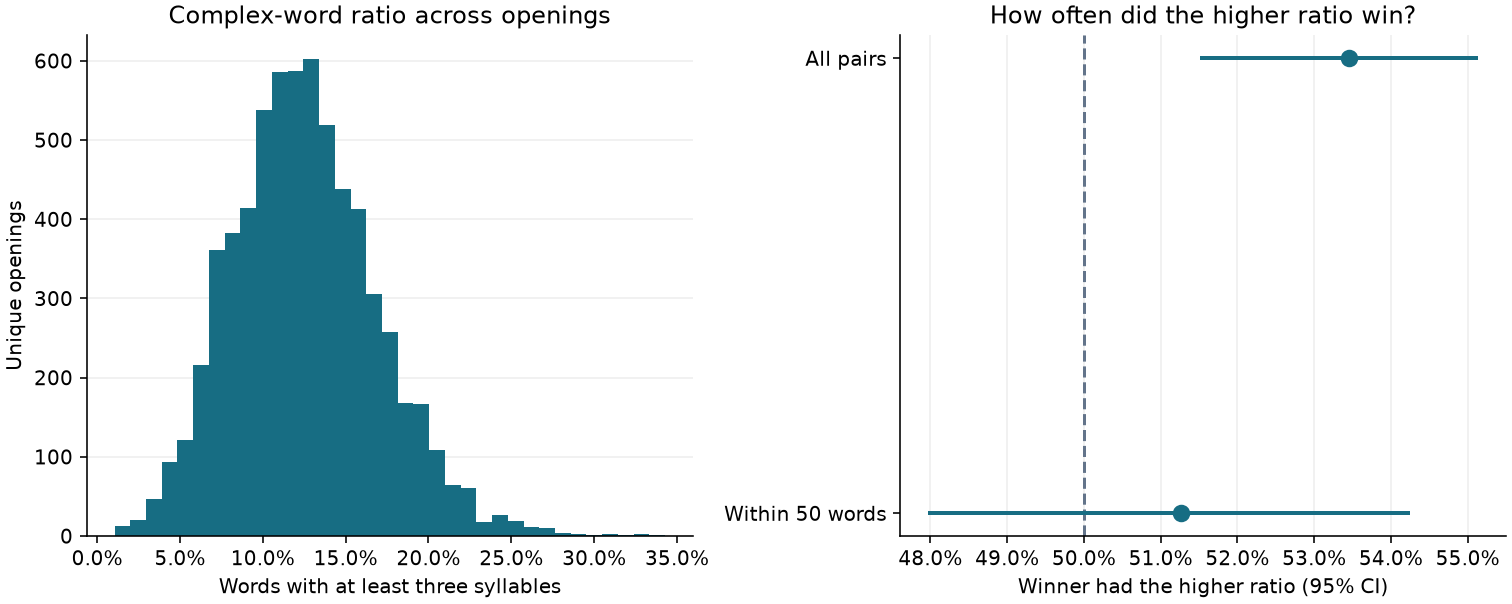

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, (distribution, paired_plot) = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
distribution.hist(openings[feature], bins=35, color="#176d83")
distribution.set(title="Complex-word ratio across openings",
                 xlabel="Words with at least three syllables", ylabel="Unique openings")
distribution.xaxis.set_major_formatter(PercentFormatter(1))
rows = np.arange(len(metrics))
paired_plot.axvline(50, linestyle="--", color="#63748a")
paired_plot.hlines(rows, metrics["95% CI lower (%)"], metrics["95% CI upper (%)"], color="#176d83", lw=2)
paired_plot.scatter(metrics["Winner higher (%)"], rows, color="#176d83", s=60, zorder=3)
paired_plot.set_yticks(rows, metrics.index.tolist())
paired_plot.invert_yaxis()
paired_plot.set(title="How often did the higher ratio win?",
                xlabel="Winner had the higher ratio (95% CI)")
paired_plot.xaxis.set_major_formatter(PercentFormatter(100))
for ax, axis in ((distribution, "y"), (paired_plot, "x")):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=axis, alpha=0.22)
    ax.set_axisbelow(True)
plt.show()

## Correlations with existing features

Pearson measures linear association and Spearman measures monotonic association. Compare across distinct opening replies and signed A-minus-B differences. The latter matches the representation used by the paired models. Both coefficients in each row use the same common cases.

In [5]:
REFERENCE_RUN_ID = "20261120T205843293180Z"
reference = RUNS.parent / "average-word-length" / REFERENCE_RUN_ID
reference_report = json.loads((reference / "results.json").read_text())
assert report["split"] == reference_report["split"] == "train"

labels = {
    "complex_word_ratio": "Complex-word ratio",
    "average_word_length": "Average word length",
    "mean_content_word_zipf": "Mean content-word Zipf",
    "word_count": "Opening word count",
}
reference_features = list(labels)[1:]
reference_openings = pd.read_parquet(reference / "opening_scores.parquet", columns=reference_features)
opening_features = openings[[feature]].join(reference_openings)
keys = ["pair_id", "post_id", "a_comment_id", "b_comment_id", "a_wins", "fold"]
reference_differences = [f"a_minus_b_{name}" for name in reference_features]
reference_pairs = pd.read_parquet(reference / "paired_scores.parquet", columns=[*keys, *reference_differences])
pair_features = pairs[[*keys, f"a_minus_b_{feature}"]].merge(
    reference_pairs, on=keys, how="inner", validate="one_to_one",
).rename(columns={f"a_minus_b_{name}": name for name in labels})

correlations = []
for unit, frame in {"Unique openings": opening_features, "A-minus-B pair differences": pair_features}.items():
    features = frame[list(labels)].dropna()
    pearson = features.corr(method="pearson")
    spearman = features.corr(method="spearman")
    for baseline in reference_features:
        correlations.append({
            "Unit": unit, "Compared with": labels[baseline], "Observations": len(features),
            "Pearson": pearson.loc[feature, baseline], "Spearman": spearman.loc[feature, baseline],
        })
display(pd.DataFrame(correlations).set_index(["Unit", "Compared with"]).round(4))

Observations  Pearson  Spearman
Unit                       Compared with                                          
Unique openings            Average word length             6581   0.8121    0.8002
                           Mean content-word Zipf          6581  -0.5082   -0.5042
                           Opening word count              6581   0.0185    0.0339
A-minus-B pair differences Average word length             3451   0.7740    0.7611
                           Mean content-word Zipf          3451  -0.5139   -0.5010
                           Opening word count              3451   0.0158    0.0163